--- Серия 1 ---
  μ = 0.443 ± 0.020
  g = 9.551 ± 0.179 м/с²

--- Серия 2 ---
  μ = 0.463 ± 0.034
  g = 9.778 ± 0.307 м/с²

--- Серия 3 ---
  μ = 0.451 ± 0.023
  g = 9.546 ± 0.210 м/с²



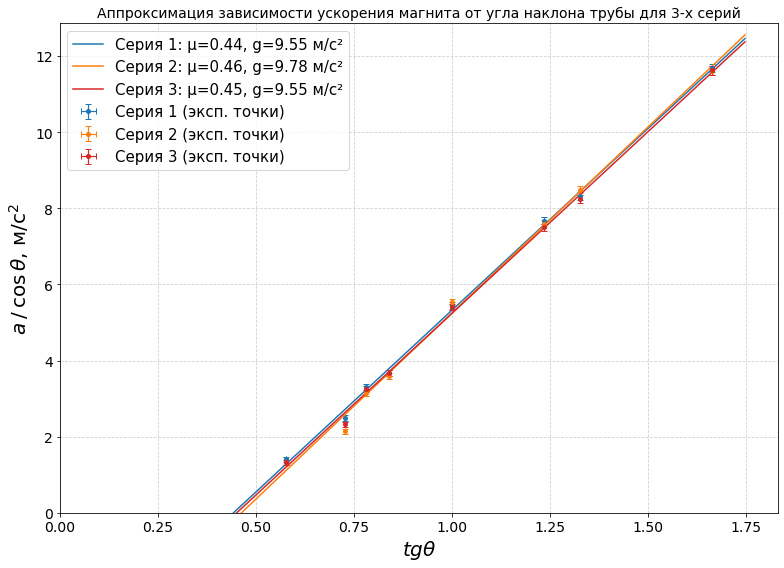

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

f = lambda x, k, b: k * x + b

# ==========================================
# 1. ИСХОДНЫЕ ДАННЫЕ ПО СЕРИЯМ ЭКСПЕРИМЕНТОВ
# ==========================================
datasets = [
    {
        "name": "Серия 1",
        "theta": np.array([30, 36, 38, 40, 45, 51, 53, 59]),
        "a": np.array([1.22, 2.01, 2.61, 2.82, 3.85, 4.83, 5.01, 6.02]),
        "sigma_theta": 0.5,  # погрешность угла (град)
        "sigma_a": 0.06,  # погрешность ускорения (м/с^2)
        "color": "tab:blue",
    },
    {
        "name": "Серия 2",
        "theta": np.array([30, 36, 38, 40, 45, 51, 53, 59]),
        "a": np.array([1.15, 1.73, 2.48, 2.75, 3.92, 4.78, 5.11, 5.98]),
        "sigma_theta": 0.5,
        "sigma_a": 0.06,
        "color": "tab:orange",
    },
    {
        "name": "Серия 3",
        "theta": np.array([30, 36, 38, 40, 45, 51, 53, 59]),
        "a": np.array([1.15, 1.88, 2.57, 2.81, 3.82, 4.72, 4.96, 5.99]),
        "sigma_theta": 0.5,
        "sigma_a": 0.06,
        "color": "tab:red",
    },
]

plt.figure(figsize=(11, 8))
plt.title(
    "Аппроксимация зависимости ускорения магнита от угла наклона трубы для 3-х серий",
    fontsize=14,
)

max_tn = 0
max_ap = 0

# ==========================================
# 2. ОБРАБОТКА И ПОСТРОЕНИЕ ДЛЯ КАЖДОЙ СЕРИИ
# ==========================================
for data in datasets:
    theta = data["theta"]
    a = data["a"]

    # Преобразуем погрешности в массивы (если они заданы одним числом)
    sigma_theta = np.full_like(theta, data["sigma_theta"])
    sigma_a = np.full_like(a, data["sigma_a"])

    # Перевод в радианы
    theta_rad = theta / 180 * np.pi
    sigma_theta_rad = sigma_theta / 180 * np.pi

    # Линеаризация
    ap = a / np.cos(theta_rad)
    tn = np.tan(theta_rad)

    # Обновление максимумов для масштаба осей
    max_tn = max(max_tn, np.max(tn))
    max_ap = max(max_ap, np.max(ap))

    # Перенос погрешностей
    sigma_cos = np.abs(np.sin(theta_rad)) * sigma_theta_rad
    sigma_tan = sigma_theta_rad / np.cos(theta_rad) ** 2
    sigma_ap = ap * np.sqrt(
        (sigma_a / a) ** 2 + (sigma_cos / np.cos(theta_rad)) ** 2
    )

    # Аппроксимация МНК
    K, err = curve_fit(f, tn, ap, sigma=sigma_ap)

    # Расчет физических параметров
    g = K[0]
    mu = -K[1] / K[0]

    sigma_g = np.sqrt(err[0][0])
    sigma_mu = mu * np.sqrt(err[0][0] / g**2 + err[1][1] / K[1] ** 2)

    # Вывод результатов в консоль
    print(f"--- {data['name']} ---")
    print(f"  μ = {mu:.3f} ± {sigma_mu:.3f}")
    print(f"  g = {g:.3f} ± {sigma_g:.3f} м/с²\n")

    label_fit = f"{data['name']}: μ={mu:.2f}, g={g:.2f} м/с²"

    # Экспериментальные точки с крестами погрешностей
    plt.errorbar(
        tn,
        ap,
        xerr=sigma_tan,
        yerr=sigma_ap,
        fmt="o",
        color=data["color"],
        ms=4,
        elinewidth=1.2,
        capsize=3,
        label=f"{data['name']} (эксп. точки)",
    )

    # Сглаженная линия аппроксимации
    x_line = np.linspace(0, np.max(tn) * 1.05, 100)
    plt.plot(
        x_line,
        f(x_line, *K),
        "-",
        color=data["color"],
        linewidth=1.5,
        label=label_fit,
    )

# ==========================================
# 3. НАСТРОЙКА ОТОБРАЖЕНИЯ
# ==========================================
plt.xlabel(r"$tg \theta$", fontsize=20)
plt.ylabel(r"$a\: /\: \cos \theta$, м/с$^2$", fontsize=20)

plt.xlim(0, 1.1 * max_tn)
plt.ylim(0, 1.1 * max_ap)
plt.xticks(fontsize=14)  # для оси X
plt.yticks(fontsize=14)  # для оси Y

plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=15, loc="upper left")
plt.tight_layout()
plt.show()